# Predição de preços de imóveis: escolha e preparação do conjunto de dados

**Etapa 1 do trabalho:** encontrar ou criar um conjunto de dados que permita prever o preço de imóveis.

**Autor:** Vinicius Machado

Este notebook registra o processo completo: quais fontes foram consideradas, por que uma delas foi escolhida, como a base foi lida, inspecionada e limpa, e uma prova de conceito mostrando que ela de fato permite prever preços. A ideia é que dê para ler de cima a baixo e entender cada decisão sem precisar de explicações externas.

**Sumário**

1. Definição do problema
2. Fontes de dados candidatas
3. Extração da base escolhida
4. Inspeção inicial
5. Diagnóstico de qualidade
6. Limpeza e preparação
7. Análise exploratória orientada à predição
8. Prova de conceito: a base permite prever preços?
9. Base final para modelagem
10. Conclusão

## 0. Ambiente: bibliotecas e configurações

Usamos só bibliotecas que já vêm instaladas no Google Colab:

- `pandas` e `numpy` para manipular os dados;
- `matplotlib` e `seaborn` para os gráficos;
- `scikit-learn` para a prova de conceito com modelos de regressão (seção 8).

As versões são impressas para fins de reprodutibilidade. A semente aleatória (`SEMENTE`) é fixada para que a divisão treino/teste e os modelos deem sempre o mesmo resultado.

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

SEMENTE = 42

print(f"Python       : {sys.version.split()[0]}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")

Python       : 3.14.7
pandas       : 3.0.5
numpy        : 2.5.2
scikit-learn : 1.9.1


# 1. Definição do problema

## 1.1 O que queremos prever

O objetivo é estimar o **preço de venda** de um imóvel a partir das suas características: localização, tamanho, número de cômodos, vagas, itens de lazer etc. Em termos de *machine learning*, é um problema de **regressão supervisionada**: precisamos de exemplos de imóveis com o preço conhecido (a variável-alvo) para que um modelo aprenda a relação entre as características e o preço.

## 1.2 O que um bom conjunto de dados precisa ter

Antes de procurar as bases, definimos os critérios que vão orientar a escolha. Assim, a decisão fica justificada e não depende de preferência pessoal.

| # | Critério | Por que importa |
|---|---|---|
| C1 | **Variável-alvo clara**: preço de **venda** | Misturar aluguel e venda, ou usar só aluguel, muda o problema |
| C2 | **Atributos explicativos** relevantes: área, quartos, banheiros, vagas, localização, lazer | Sem eles o modelo não tem de onde aprender |
| C3 | **Volume** suficiente (milhares de registros) | Mais exemplos permitem modelos mais robustos e uma avaliação confiável |
| C4 | **Atualidade** | Preço de imóvel muda com o tempo; dados antigos descrevem outro mercado |
| C5 | **Acesso reprodutível** | Qualquer pessoa deve conseguir rodar o notebook do zero, sem login nem *upload* manual |
| C6 | **Qualidade** razoável | Poucos ausentes e erros que possam ser tratados com regras claras |

# 2. Fontes de dados candidatas

## 2.1 As opções levantadas

Foram consideradas quatro fontes:

**A. Imóveis de São Paulo, abril de 2019 (Kaggle)**
cerca de 13 mil registros com `Price`, `Condo`, `Size`, `Rooms`, `Toilets`, `Suites`, `Parking`, `Elevator`, `Furnished`, `Swimming Pool`, `New`, `District`, `Negotiation Type`, `Property Type`, `Latitude` e `Longitude`.
<https://www.kaggle.com/datasets/argonalyst/sao-paulo-real-estate-sale-rent-april-2019>

**B. Imóveis de São Paulo, 2023, QuintoAndar (Kaggle)**
quase 12 mil registros com `Address`, `District`, `Area`, `Bedrooms`, `Garage`, `Rent`, `Type` e `Total`.
<https://www.kaggle.com/datasets/renatosn/sao-paulo-housing-prices>

**C. Biblioteca `dadosimob` (GitHub)**
biblioteca Python que busca dados públicos e atualizados de transações de imóveis.
<https://github.com/Rafaxdz-1000/dadosimob>

**D. Imóveis à venda no Rio de Janeiro, outubro de 2026, QuintoAndar**
coleta de anúncios de venda do QuintoAndar no município do Rio, disponível em CSV público.
<https://raw.githubusercontent.com/alvaroriz/datascience_datasets/refs/heads/main/quintoandar_rio_20261005.csv>

## 2.2 Comparação pelos critérios

| Critério | A. SP 2019 | B. SP 2023 | C. `dadosimob` | D. Rio 2026 |
|---|---|---|---|---|
| C1 Alvo = preço de venda | Parcial: mistura venda e aluguel (`Negotiation Type`), só uma parte é venda | **Não**: só aluguel (`Rent`, `Total`) | Sim: valor de transação | **Sim**: só venda |
| C2 Atributos | Bons, inclusive coordenadas | Poucos: área, quartos, vagas, tipo | Dependem da fonte consultada; em geral poucos atributos físicos | **Bons**: área, quartos, banheiros, suítes, vagas, condomínio, lazer, bairro e região |
| C3 Volume | ~13 mil, menos depois de filtrar só venda | ~12 mil | Variável | **~41 mil** |
| C4 Atualidade | 2019, defasada | 2023 | Atual | **Outubro de 2026** |
| C5 Acesso reprodutível | Exige conta no Kaggle | Exige conta no Kaggle | Depende de instalação e de serviços externos | **URL pública direta** |

## 2.3 Decisão

**Escolhemos a base D (QuintoAndar Rio, 2026).** Ela é a única que atende a todos os critérios ao mesmo tempo:

- traz **somente preço de venda**, então o alvo já é o que queremos prever, sem filtros que reduzam a base (ao contrário de A) e sem trocar de problema (ao contrário de B);
- tem o **maior volume** e o **conjunto mais rico de atributos**;
- é a mais **atual**;
- pode ser lida **direto pela URL**, o que torna o notebook reprodutível no Colab.

As outras fontes não são descartadas por serem ruins: a base A seria uma boa alternativa para São Paulo se filtrássemos só os anúncios de venda, e a `dadosimob` é interessante para complementar com transações reais (o preço anunciado não é necessariamente o preço fechado). Essa limitação da base D é registrada na conclusão.

O critério C6 (qualidade) não pode ser avaliado antes de abrir os dados. É o que fazemos nas seções 4 e 5.

# 3. Extração da base escolhida

## 3.1 Leitura direto da URL

A base é lida diretamente do repositório público, sem *download* manual. Guardamos essa versão original em `df_raw` e **nunca a modificamos**: toda a limpeza é feita em uma cópia. Assim, sempre dá para comparar o antes e o depois e medir o impacto de cada decisão.

O arquivo está em UTF-8, e por isso informamos `encoding="utf-8"` para que os acentos dos bairros (por exemplo, "Jacarepaguá") sejam lidos corretamente.

In [2]:
URL = "https://raw.githubusercontent.com/alvaroriz/datascience_datasets/refs/heads/main/quintoandar_rio_20261005.csv"

df_raw = pd.read_csv(URL, encoding="utf-8")

print(f"Linhas : {df_raw.shape[0]:,}")
print(f"Colunas: {df_raw.shape[1]}")
df_raw.head()

Linhas : 41,450
Colunas: 22


,id_fonte,origem,url,tipo,subtipo,bairro,regiao,preco,area_m2,preco_m2,quartos,banheiros,suites,vagas,condominio_iptu,tem_piscina,tem_churrasqueira,tem_academia,tem_varanda,mobiliado,lancamento,data_coleta
0,894754964,quintoandar,https://www.quintoandar.com.br/imovel/89475496...,apartamento,apartamento,Anil,Barra e Jacarepaguá,150000,47,3191,2.00,1.00,0,1.00,300,0,0,0,0,0,0,2026-10-05
1,894763874,quintoandar,https://www.quintoandar.com.br/imovel/89476387...,apartamento,apartamento,Anil,Barra e Jacarepaguá,150000,44,3409,2.00,1.00,0,1.00,200,0,0,0,1,0,0,2026-10-05
2,111152175,classificado,https://www.quintoandar.com.br/classificado/11...,apartamento,apartamento,Anil,Barra e Jacarepaguá,159830,55,2906,2.00,1.00,0,1.00,240,0,0,0,0,0,0,2026-10-05
3,129473777,classificado,https://www.quintoandar.com.br/classificado/12...,apartamento,apartamento,Anil,Barra e Jacarepaguá,170000,44,3864,2.00,1.00,0,1.00,220,0,0,0,0,0,0,2026-10-05
4,117375903,classificado,https://www.quintoandar.com.br/classificado/11...,apartamento,apartamento,Anil,Barra e Jacarepaguá,170000,48,3542,2.00,1.00,0,1.00,510,0,1,0,0,0,0,2026-10-05


# 4. Inspeção inicial

## 4.1 Dicionário de dados

Antes de qualquer análise, precisamos saber o que cada coluna significa e qual papel ela pode ter na predição. A coluna "Papel" antecipa a decisão sobre o uso de cada variável:

- **alvo**: o que queremos prever;
- **atributo**: entra no modelo como variável explicativa;
- **excluir**: não entra no modelo, e o motivo é explicado.

| Coluna | Descrição | Papel |
|---|---|---|
| `id_fonte` | Código do anúncio na fonte | excluir: identificador, não descreve o imóvel |
| `origem` | `quintoandar` (anúncio próprio) ou `classificado` (anúncio de terceiros na plataforma) | atributo: o tipo de anúncio pode influenciar o preço pedido |
| `url` | Endereço do anúncio | excluir: identificador |
| `tipo` | `apartamento` ou `casa` | atributo |
| `subtipo` | `apartamento`, `kitnet`, `casa`, `casa_condominio` | atributo (mais detalhado que `tipo`) |
| `bairro` | Bairro do imóvel | atributo: a localização é um dos principais fatores de preço |
| `regiao` | Região da cidade (Zona Sul, Zona Norte etc.) | atributo |
| `preco` | Preço de venda anunciado (R$) | **alvo** |
| `area_m2` | Área útil (m²) | atributo |
| `preco_m2` | Preço por m² (`preco / area_m2`) | **excluir: vazamento de dados**, explicado na seção 4.3 |
| `quartos`, `banheiros`, `suites`, `vagas` | Contagens de cômodos e vagas | atributos |
| `condominio_iptu` | Condomínio + IPTU mensal (R$) | atributo |
| `tem_piscina`, `tem_churrasqueira`, `tem_academia`, `tem_varanda` | Indicadores 0/1 de lazer | atributos |
| `mobiliado` | Indicador 0/1 | atributo |
| `lancamento` | Indicador 0/1 de imóvel na planta | avaliar: pode ser quase constante |
| `data_coleta` | Data da coleta | avaliar: pode ser constante |

## 4.2 Tipos e valores ausentes

Conferimos se cada coluna foi lida com o tipo certo (números como números, textos como textos) e quantos valores faltam em cada uma. Isso mostra se precisamos converter tipos e onde vamos precisar tratar ausentes.

In [3]:
resumo = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "ausentes": df_raw.isna().sum(),
    "% ausentes": (df_raw.isna().mean() * 100).round(2),
    "valores distintos": df_raw.nunique(),
})
resumo

,tipo,ausentes,% ausentes,valores distintos
id_fonte,int64,0,0.00,41450
origem,str,0,0.00,2
url,str,0,0.00,41450
tipo,str,0,0.00,2
subtipo,str,0,0.00,4
bairro,str,0,0.00,206
regiao,str,66,0.16,6
preco,int64,0,0.00,5832
area_m2,int64,0,0.00,890
preco_m2,int64,0,0.00,13205


**Leitura do resultado:**

- Todas as colunas numéricas foram lidas como números. `quartos`, `banheiros` e `vagas` aparecem como `float` só porque têm alguns ausentes (o `pandas` não guarda ausentes em colunas inteiras comuns).
- Há poucos ausentes: `regiao`, `banheiros`, `quartos` e `vagas`, todos abaixo de 0,2% das linhas. É um ótimo sinal para o critério C6.
- `data_coleta` tem **um único valor**: todos os anúncios foram coletados no mesmo dia. Ela não ajuda a explicar diferenças de preço e será excluída.
- `url` e `id_fonte` têm um valor por linha, como esperado de identificadores.

## 4.3 Estatísticas descritivas e o vazamento em `preco_m2`

As estatísticas dão uma primeira ideia das escalas e de possíveis valores estranhos (mínimos e máximos fora do razoável).

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
id_fonte,"41,450.00","544,438,549.18","384,790,857.57","100,000,003.00","124,461,553.25","893,461,769.00","895,225,003.75","895,771,995.00"
preco,"41,450.00","1,386,611.94","1,826,931.78","125,000.00","399,000.00","780,000.00","1,600,000.00","20,000,000.00"
area_m2,"41,450.00",161.53,165.39,15.00,68.00,103.00,195.00,"4,500.00"
preco_m2,"41,450.00","8,919.13","6,325.16",971.00,"4,444.00","7,083.00","11,409.00","41,111.00"
quartos,"41,447.00",2.81,1.14,0.00,2.00,3.00,3.00,10.00
banheiros,"41,401.00",2.56,1.57,1.00,1.00,2.00,3.00,12.00
suites,"41,450.00",1.11,1.23,0.00,0.00,1.00,2.00,9.00
vagas,"41,448.00",1.49,1.30,0.00,1.00,1.00,2.00,10.00
condominio_iptu,"41,450.00","2,583.25","32,121.14",-1.00,400.00,"1,046.00","2,181.00","3,313,147.00"
tem_piscina,"41,450.00",0.40,0.49,0.00,0.00,0.00,1.00,1.00


Pontos de atenção:

- `preco` vai de R$ 125 mil a R$ 20 milhões, e a média é bem maior que a mediana. A distribuição é **muito assimétrica** (poucos imóveis muito caros), o que vamos tratar com logaritmo na seção 7.
- `condominio_iptu` tem mínimo **negativo** e máximo de mais de **R$ 3 milhões por mês**, valores impossíveis que indicam erro de digitação no anúncio.
- `area_m2` chega a 4.500 m², o que precisa ser checado.

Sobre `preco_m2`: a célula abaixo confirma que ela é só `preco / area_m2` arredondado. Se ela entrasse no modelo, bastaria multiplicá-la pela área para obter o preço exato. O modelo pareceria excelente nos testes, mas seria inútil na prática, porque **para um imóvel novo nós não sabemos o preço por m² sem saber o preço**. Esse problema se chama **vazamento de dados** (*data leakage*). Por isso `preco_m2` não será usada como atributo. Ela continua útil para a limpeza, pois ajuda a detectar anúncios com área ou preço digitados errado.

In [5]:
diferenca = (df_raw["preco_m2"] - df_raw["preco"] / df_raw["area_m2"]).abs()
print(f"Maior diferença entre preco_m2 e preco/area_m2: {diferenca.max():.2f} (apenas arredondamento)")

Maior diferença entre preco_m2 e preco/area_m2: 0.50 (apenas arredondamento)


## 4.4 Variáveis categóricas

Olhamos as categorias de cada variável de texto para verificar se estão padronizadas e se há categorias raras demais.

In [6]:
for coluna in ["origem", "tipo", "subtipo", "regiao"]:
    print(f"--- {coluna} ---")
    print(df_raw[coluna].value_counts(dropna=False).to_string(), end="\n\n")

contagem_bairros = df_raw["bairro"].value_counts()
print(f"--- bairro ---\n{contagem_bairros.size} bairros distintos")
print(f"Bairros com menos de 20 anúncios: {(contagem_bairros < 20).sum()}")
contagem_bairros.head(10)

--- origem ---
origem
quintoandar     22652
classificado    18798

--- tipo ---
tipo
apartamento    31703
casa            9747

--- subtipo ---
subtipo
apartamento        31353
casa                6416
casa_condominio     3331
kitnet               350

--- regiao ---
regiao
Barra e Jacarepaguá    18357
Zona Sul                8318
Zona Norte              7154
Grande Tijuca           4010
Centro                  1845
Zona Oeste              1700
NaN                       66

--- bairro ---
206 bairros distintos
Bairros com menos de 20 anúncios: 81


bairro
Barra da Tijuca             5283
Recreio dos Bandeirantes    4356
Copacabana                  2636
Tijuca                      1855
Taquara                     1558
Botafogo                    1520
Jacarepaguá                 1376
Freguesia (Jacarepaguá)     1211
Campo Grande                1028
Méier                        799
Name: count, dtype: int64

**Leitura do resultado:**

- `tipo` e `subtipo` são coerentes: todo `kitnet` é `apartamento` e todo `casa_condominio` é `casa`. Por isso `subtipo` carrega toda a informação de `tipo` e um pouco mais.
- `lancamento` (seção 4.3) tem média próxima de zero: quase nenhum imóvel é lançamento, então essa variável quase não varia e será excluída.
- Há **206 bairros**, e muitos com pouquíssimos anúncios. Um modelo não consegue aprender o efeito de um bairro que aparece 2 ou 3 vezes. Vamos agrupar os bairros raros na seção 6.
- `regiao` tem 66 ausentes, analisados a seguir.

# 5. Diagnóstico de qualidade

Nesta seção listamos os problemas encontrados, com a evidência de cada um. As decisões de tratamento ficam para a seção 6, para separar o **diagnóstico** (o que está errado) da **ação** (o que fazemos a respeito).

## 5.1 Linhas sem região: bairros inválidos

In [7]:
sem_regiao = df_raw[df_raw["regiao"].isna()]
print(f"Linhas sem região: {len(sem_regiao)}")
sem_regiao["bairro"].value_counts().head(15)

Linhas sem região: 66


bairro
ジャルジン・サン・フランシスコ・デ・アシス      20
Icaraí                      5
Argentino                   2
Dumas                       2
Niteroi                     2
conjunto Cesar Maia         2
332                         1
800                         1
900                         1
Arujázinho I, Ii e Iii      1
Bairro Riachuelo            1
Bota Fogo                   1
Campo Grande NUMERO 270     1
Campo Grande23              1
Ciro Aranha                 1
Name: count, dtype: int64

Os anúncios sem região são justamente os que têm o **bairro preenchido de forma inválida**: nomes em outro alfabeto, números ("332", "800"), bairros de Niterói (Icaraí) e grafias livres ("Recreio dos Bandeir", "Campo Grande23"). A plataforma não conseguiu associá-los a uma região porque o bairro não é reconhecido. Como a localização é central para o preço, esses registros têm a informação mais importante comprometida.

## 5.2 Condomínio + IPTU impossível

Avaliamos `condominio_iptu` em relação ao preço do imóvel. Um custo mensal acima de 1% do valor do imóvel significaria pagar mais de 12% do valor por ano só de condomínio e IPTU, o que não acontece na prática (a mediana da base fica perto de 0,14% ao mês).

In [8]:
razao_condominio = df_raw["condominio_iptu"] / df_raw["preco"]

print(f"Valores negativos            : {(df_raw['condominio_iptu'] < 0).sum()}")
print(f"Valores iguais a zero        : {(df_raw['condominio_iptu'] == 0).sum()}")
print(f"Mensal > 1% do preço         : {(razao_condominio > 0.01).sum()}")
print(f"Mediana (condomínio / preço) : {razao_condominio.median():.4%}")

df_raw.loc[razao_condominio > 0.01, ["subtipo", "bairro", "preco", "area_m2", "condominio_iptu"]] \
    .sort_values("condominio_iptu", ascending=False).head(8)

Valores negativos            : 110
Valores iguais a zero        : 4713
Mensal > 1% do preço         : 132
Mediana (condomínio / preço) : 0.1432%


,subtipo,bairro,preco,area_m2,condominio_iptu
4049,apartamento,Barra da Tijuca,2637573,188,3313147
14803,casa_condominio,Recreio dos Bandeirantes,2825000,334,2900550
38825,apartamento,Ipanema,1990000,85,2337917
38720,apartamento,Ipanema,1470000,72,1550365
6074,casa_condominio,Barra da Tijuca,7400000,629,1524317
12761,apartamento,Recreio dos Bandeirantes,900000,112,1381334
8092,casa_condominio,Freguesia (Jacarepaguá),1290000,260,1323905
11963,apartamento,Recreio dos Bandeirantes,690000,83,1224584


Os exemplos mostram imóveis de R$ 700 mil a R$ 7 milhões com condomínio + IPTU acima de **R$ 1 milhão por mês**, claramente erros de digitação (provavelmente centavos digitados sem a vírgula ou valores anuais somados). Os valores negativos também são impossíveis.

Já o **zero** é plausível em muitos casos: casas de rua normalmente não têm condomínio, e há imóveis isentos de IPTU. Por isso o zero não será tratado como erro.

## 5.3 Preço por m² fora do padrão do mercado

Um anúncio com a área digitada errada (por exemplo, 4.500 m² em vez de 45 m²) gera um preço por m² muito diferente do que se pratica naquele tipo de imóvel e naquela região. Para detectar esses casos usamos um critério **robusto**, a mediana e o MAD (desvio absoluto mediano), calculado **por região e subtipo**, porque o m² na Zona Sul é bem mais caro que na Zona Oeste e não faz sentido comparar os dois.

O procedimento é este:

1. trabalhamos com `log(preco_m2)`, porque em escala logarítmica a distribuição fica simétrica;
2. dentro de cada grupo (região × subtipo), calculamos a distância de cada anúncio até a mediana do grupo, medida em MADs;
3. marcamos como atípico quem estiver a mais de 3,5 MADs (escalados) da mediana, um limite usual na literatura de detecção de *outliers* (Iglewicz e Hoaglin).

Usamos mediana e MAD em vez de média e desvio-padrão porque os próprios *outliers* puxam a média e inflam o desvio-padrão, o que esconderia justamente os casos que queremos encontrar.

In [9]:
LIMITE_MAD = 3.5


def escore_robusto(serie):
    """Distância à mediana em unidades de MAD escalado (equivalente a desvios-padrão em dados normais)."""
    mediana = serie.median()
    mad = (serie - mediana).abs().median() * 1.4826
    return (serie - mediana) / mad if mad > 0 else serie * 0


log_m2 = np.log(df_raw["preco_m2"])
escore_m2 = log_m2.groupby([df_raw["regiao"], df_raw["subtipo"]]).transform(escore_robusto)
atipico_m2 = escore_m2.abs() > LIMITE_MAD

print(f"Anúncios com preço/m² atípico: {atipico_m2.sum()} ({atipico_m2.mean():.2%})")
df_raw.loc[atipico_m2, ["subtipo", "bairro", "regiao", "preco", "area_m2", "preco_m2"]] \
    .sort_values("preco_m2").head(8)

Anúncios com preço/m² atípico: 84 (0.20%)


,subtipo,bairro,regiao,preco,area_m2,preco_m2
40267,casa,Laranjeiras,Zona Sul,1800000,1212,1485
33066,apartamento,Botafogo,Zona Sul,195000,75,2600
33067,apartamento,Botafogo,Zona Sul,200000,75,2667
39330,apartamento,Jardim Botânico,Zona Sul,750000,280,2679
34484,apartamento,Botafogo,Zona Sul,3400000,1164,2921
34444,apartamento,Botafogo,Zona Sul,3000000,1000,3000
32974,apartamento,Santa Cruz,Zona Oeste,2280000,161,14161
32478,apartamento,Cosmos,Zona Oeste,1690000,118,14322


Os casos marcados são combinações incoerentes: na Zona Sul, apartamentos com m² abaixo de R$ 3 mil (áreas de mais de 1.000 m² em Botafogo ou preços de R$ 200 mil, quando o m² típico da região passa de R$ 14 mil); na Zona Oeste, m² acima de R$ 14 mil, quase quatro vezes o típico da região. Representam só 0,2% da base.

## 5.4 Inconsistências entre cômodos

Verificamos se há mais suítes do que quartos, o que é impossível, já que toda suíte é um quarto.

In [10]:
suites_demais = df_raw["suites"] > df_raw["quartos"]
print(f"Anúncios com mais suítes que quartos: {suites_demais.sum()}")
df_raw.loc[suites_demais, ["subtipo", "quartos", "suites", "banheiros", "area_m2"]].head()

Anúncios com mais suítes que quartos: 38


,subtipo,quartos,suites,banheiros,area_m2
1122,apartamento,2.00,4,4.00,143
1253,apartamento,2.00,3,3.00,77
2374,apartamento,0.00,2,2.00,69
2736,apartamento,0.00,1,3.00,145
2750,apartamento,1.00,2,1.00,171


Outras relações que **parecem** inconsistentes, mas não são erros, ficaram de fora deste diagnóstico:

- **menos banheiros que suítes:** muitos anúncios contam em `banheiros` apenas os banheiros sociais, sem os das suítes;
- **zero quartos:** corresponde a estúdios e lofts, que têm um ambiente integrado.

## 5.5 Duplicatas

Um mesmo imóvel anunciado duas vezes teria peso dobrado no modelo e poderia cair ao mesmo tempo no treino e no teste, inflando artificialmente o desempenho.

In [11]:
colunas_imovel = [c for c in df_raw.columns if c not in ["id_fonte", "url", "origem", "data_coleta"]]
print(f"IDs repetidos                                 : {df_raw['id_fonte'].duplicated().sum()}")
print(f"Linhas idênticas em todas as características  : {df_raw.duplicated(subset=colunas_imovel).sum()}")

IDs repetidos                                 : 0


Linhas idênticas em todas as características  : 0


Não há duplicatas: nem de identificador, nem de anúncios idênticos em todas as características.

## 5.6 Resumo do diagnóstico

| # | Problema | Linhas afetadas | Gravidade |
|---|---|---|---|
| P1 | Bairro inválido, sem região | 66 | Alta: localização comprometida |
| P2 | `condominio_iptu` negativo ou acima de 1% do preço ao mês | ver 5.2 | Média: um atributo errado, o resto do anúncio pode ser aproveitado |
| P3 | Preço/m² atípico para a região e o subtipo | ver 5.3 | Alta: indica área ou preço errado, ou seja, o alvo ou um atributo central |
| P4 | Mais suítes que quartos | ver 5.4 | Baixa |
| P5 | Ausentes em `quartos`, `banheiros`, `vagas` | ~50 | Baixa |
| P6 | Bairros com pouquíssimos anúncios | 81 bairros | Média: o modelo não aprende o efeito deles |
| P7 | `preco_m2` deriva do alvo | todas | Alta: vazamento de dados |
| P8 | `data_coleta` constante e `lancamento` quase constante | todas | Baixa: colunas sem informação |

# 6. Limpeza e preparação

## 6.1 Princípios

- **Remover linhas só quando a informação central (preço, área ou localização) não é confiável.** Quando o erro está em um atributo secundário, apagamos apenas o valor (transformamos em ausente) e preservamos o anúncio.
- **Não imputar ausentes aqui.** O preenchimento (por exemplo, pela mediana) é feito dentro do *pipeline* do modelo e aprendido **só com os dados de treino** (seção 8). Se imputássemos agora, usando a base inteira, informação do conjunto de teste vazaria para o treino.
- **Registrar o impacto** de cada passo no número de linhas.

## 6.2 Aplicação das regras

Cada regra corresponde a um problema da seção 5.6.

In [12]:
df = df_raw.copy()
registro = [("Base original", len(df))]

# P1: bairro inválido (sem região) -> remover, a localização é central para o preço
df = df[df["regiao"].notna()]
registro.append(("P1: remover bairro inválido (sem região)", len(df)))

# P3: preço/m² atípico para a região e o subtipo -> remover, preço ou área não são confiáveis
df = df[~atipico_m2.loc[df.index]]
registro.append(("P3: remover preço/m² atípico", len(df)))

# P2: condomínio + IPTU impossível -> apagar só o valor, o anúncio é mantido
condominio_invalido = (df["condominio_iptu"] < 0) | (df["condominio_iptu"] > 0.01 * df["preco"])
df.loc[condominio_invalido, "condominio_iptu"] = np.nan
print(f"P2: valores de condomínio+IPTU apagados: {condominio_invalido.sum()}")

# P4: mais suítes que quartos -> apagar só o valor de suítes
suites_invalidas = df["suites"] > df["quartos"]
df.loc[suites_invalidas, "suites"] = np.nan
print(f"P4: valores de suítes apagados: {suites_invalidas.sum()}")

# P7 e P8: colunas que não entram no modelo
COLUNAS_EXCLUIDAS = ["id_fonte", "url", "preco_m2", "data_coleta", "lancamento", "tipo"]
df = df.drop(columns=COLUNAS_EXCLUIDAS).reset_index(drop=True)

impacto = pd.DataFrame(registro, columns=["etapa", "linhas"])
impacto["removidas"] = -impacto["linhas"].diff().fillna(0).astype(int)
impacto

P2: valores de condomínio+IPTU apagados: 241
P4: valores de suítes apagados: 38


,etapa,linhas,removidas
0,Base original,41450,0
1,P1: remover bairro inválido (sem região),41384,66
2,P3: remover preço/m² atípico,41300,84


`tipo` também foi excluída, porque é redundante com `subtipo` (seção 4.4). Manter as duas só repetiria a mesma informação no modelo.

## 6.3 Conferência do resultado

Conferimos se as regras surtiram efeito: não pode sobrar região ausente, condomínio negativo ou exagerado, nem mais suítes que quartos.

In [13]:
assert df["regiao"].notna().all()
assert not (df["condominio_iptu"] < 0).any()
assert not (df["condominio_iptu"] > 0.01 * df["preco"]).any()
assert not (df["suites"] > df["quartos"]).any()
assert not set(COLUNAS_EXCLUIDAS) & set(df.columns)

print(f"Base limpa: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Linhas preservadas: {len(df) / len(df_raw):.2%}")
print("\nAusentes restantes (serão imputados no pipeline do modelo):")
print(df.isna().sum()[lambda s: s > 0].to_string())

Base limpa: 41,300 linhas x 16 colunas
Linhas preservadas: 99.64%

Ausentes restantes (serão imputados no pipeline do modelo):
quartos              3
banheiros           48
suites              38
vagas                2
condominio_iptu    241


# 7. Análise exploratória orientada à predição

O objetivo aqui não é descrever a base inteira, e sim responder a uma pergunta: **os atributos disponíveis têm relação com o preço?** Se tiverem, há sinal para um modelo aprender.

## 7.1 Distribuição do preço e transformação logarítmica

O preço é muito assimétrico: há muitos imóveis baratos e poucos muito caros. Modelos de regressão costumam funcionar melhor quando o alvo é aproximadamente simétrico, e os erros em imóveis caros não deveriam dominar a avaliação. A solução usual é modelar `log(preco)`. Nessa escala, o erro passa a ser **relativo** (errar R$ 50 mil em um imóvel de R$ 200 mil pesa mais do que em um de R$ 5 milhões), o que faz sentido para o mercado imobiliário.

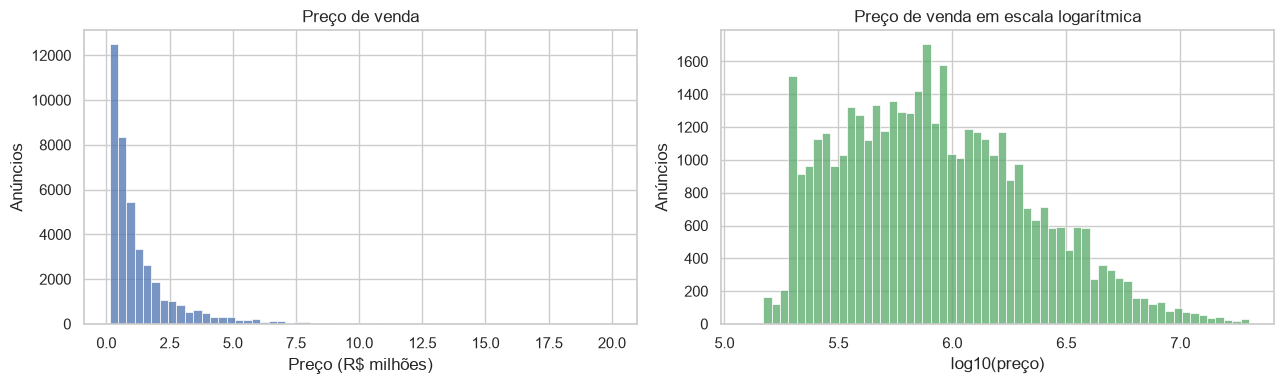

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["preco"] / 1e6, bins=60, ax=eixos[0], color="#4C72B0")
eixos[0].set(title="Preço de venda", xlabel="Preço (R$ milhões)", ylabel="Anúncios")

sns.histplot(np.log10(df["preco"]), bins=60, ax=eixos[1], color="#55A868")
eixos[1].set(title="Preço de venda em escala logarítmica", xlabel="log10(preço)", ylabel="Anúncios")

plt.tight_layout()
plt.show()

À esquerda, a cauda longa à direita. À direita, depois do log, a distribuição fica próxima de uma curva em sino. Daqui em diante o modelo prevê `log(preco)`, e as métricas são convertidas de volta para reais.

## 7.2 Área: o principal fator de preço

Esperamos que imóveis maiores custem mais. Nos dois eixos em escala logarítmica, a relação deve aparecer como uma faixa inclinada.

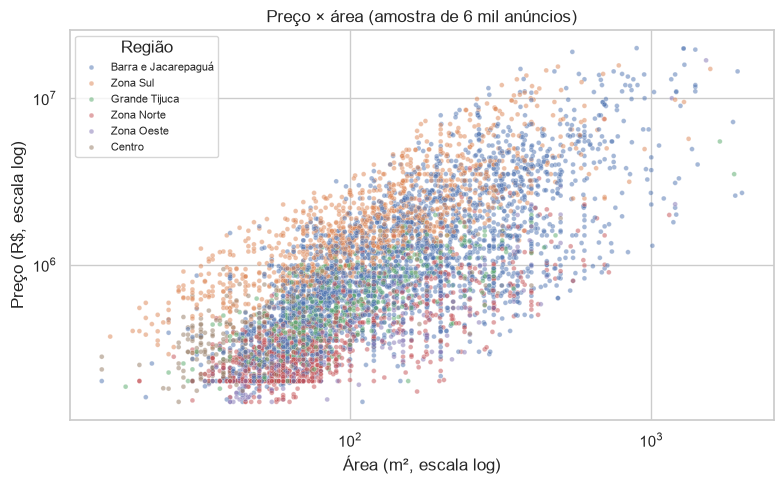

Correlação entre log(área) e log(preço): 0.72


In [15]:
amostra = df.sample(6000, random_state=SEMENTE)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=amostra, x="area_m2", y="preco", hue="regiao", s=12, alpha=0.5, ax=ax)
ax.set(xscale="log", yscale="log", title="Preço × área (amostra de 6 mil anúncios)",
       xlabel="Área (m², escala log)", ylabel="Preço (R$, escala log)")
ax.legend(title="Região", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Correlação entre log(área) e log(preço): {np.corrcoef(np.log(df['area_m2']), np.log(df['preco']))[0, 1]:.2f}")

A relação é forte e quase linear em escala log-log. As cores mostram que, **para a mesma área**, a região desloca o preço para cima ou para baixo (a Zona Sul fica acima). Ou seja, área e localização se complementam.

## 7.3 Localização: preço do m² por região

Para isolar o efeito da localização, comparamos o **preço por m²**, que neutraliza a diferença de tamanho. Aqui usar `preco_m2` não é problema, porque estamos só descrevendo os dados, não alimentando o modelo.

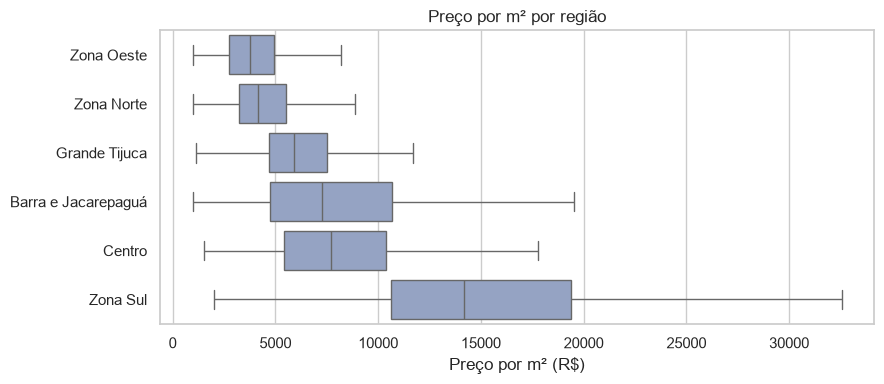

In [16]:
ordem = df.assign(preco_m2=df["preco"] / df["area_m2"]).groupby("regiao")["preco_m2"].median().sort_values().index

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df.assign(preco_m2=df["preco"] / df["area_m2"]), x="preco_m2", y="regiao",
            order=ordem, showfliers=False, color="#8DA0CB", ax=ax)
ax.set(title="Preço por m² por região", xlabel="Preço por m² (R$)", ylabel="")
plt.tight_layout()
plt.show()

O m² mediano na Zona Sul é mais que o triplo do da Zona Oeste. A localização tem um efeito enorme, o que confirma que `regiao` e `bairro` precisam entrar no modelo.

## 7.4 Demais atributos

Comparamos o preço mediano segundo o número de vagas e os itens de lazer, para verificar se esses atributos também carregam sinal.

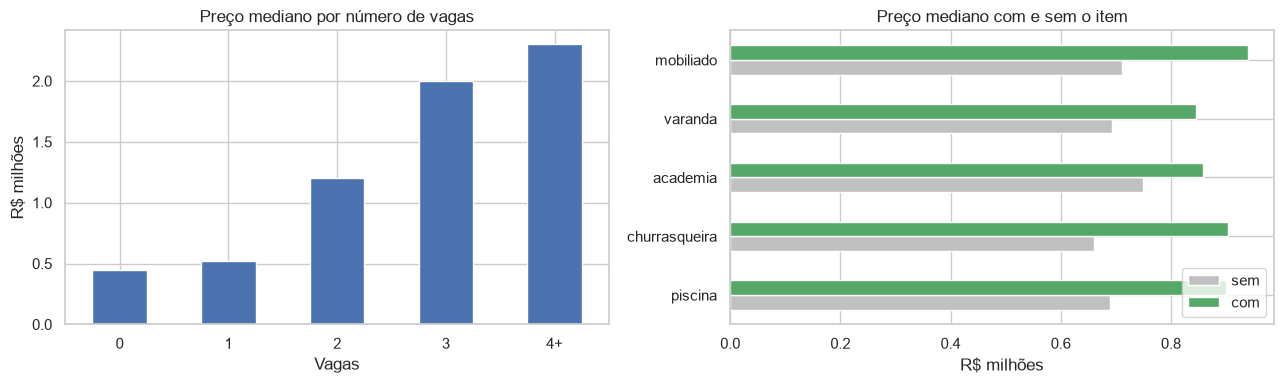

In [17]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

vagas = df.assign(vagas_grp=df["vagas"].clip(upper=4)).groupby("vagas_grp")["preco"].median() / 1e6
vagas.index = [f"{int(v)}" if v < 4 else "4+" for v in vagas.index]
vagas.plot.bar(ax=eixos[0], color="#4C72B0", rot=0)
eixos[0].set(title="Preço mediano por número de vagas", xlabel="Vagas", ylabel="R$ milhões")

lazer = ["tem_piscina", "tem_churrasqueira", "tem_academia", "tem_varanda", "mobiliado"]
efeito = pd.DataFrame({
    "sem": [df.loc[df[c] == 0, "preco"].median() / 1e6 for c in lazer],
    "com": [df.loc[df[c] == 1, "preco"].median() / 1e6 for c in lazer],
}, index=[c.replace("tem_", "") for c in lazer])
efeito.plot.barh(ax=eixos[1], color=["#C0C0C0", "#55A868"])
eixos[1].legend(loc="lower right")
eixos[1].set(title="Preço mediano com e sem o item", xlabel="R$ milhões", ylabel="")

plt.tight_layout()
plt.show()

O preço cresce de forma consistente com o número de vagas, e os imóveis com piscina, academia ou churrasqueira têm preço mediano maior. Parte desse efeito vem do tamanho (imóveis maiores costumam ter mais vagas e lazer), mas é exatamente esse tipo de relação combinada que um modelo de *machine learning* consegue separar.

**Conclusão da exploração:** todos os grupos de atributos (tamanho, localização, cômodos e lazer) mostram relação com o preço. A base tem sinal para a predição.

# 8. Prova de conceito: a base permite prever preços?

A melhor maneira de confirmar que o conjunto de dados serve para o objetivo é **treinar modelos e medir o erro em dados que eles nunca viram**. Não é a modelagem final (que é uma etapa posterior do trabalho), e sim um teste de viabilidade.

## 8.1 Separação entre treino e teste

Separamos 20% dos anúncios como **conjunto de teste**, guardado para a avaliação final. Tudo o que o modelo aprende (inclusive as medianas de imputação e a lista de bairros frequentes) sai apenas dos 80% de **treino**. Isso simula a situação real: o modelo é construído com dados conhecidos e aplicado a imóveis novos.

Estratificamos pela região para que treino e teste tenham a mesma proporção de anúncios de cada região.

In [18]:
from sklearn.model_selection import train_test_split

ALVO = "preco"
X = df.drop(columns=[ALVO])
y = np.log(df[ALVO])  # modelamos log(preço), ver seção 7.1

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE, stratify=df["regiao"]
)
print(f"Treino: {len(X_treino):,} anúncios | Teste: {len(X_teste):,} anúncios")

Treino: 33,040 anúncios | Teste: 8,260 anúncios


## 8.2 Agrupamento dos bairros raros (P6)

Bairros com menos de 20 anúncios **no treino** passam a ser rotulados como "Outros (região)". Assim o modelo usa o efeito médio da região para eles, em vez de tentar aprender um efeito a partir de dois ou três exemplos. A lista de bairros frequentes é calculada só no treino e depois aplicada ao teste.

In [19]:
MIN_ANUNCIOS_BAIRRO = 20
bairros_frequentes = X_treino["bairro"].value_counts()
bairros_frequentes = set(bairros_frequentes[bairros_frequentes >= MIN_ANUNCIOS_BAIRRO].index)


def agrupar_bairros(X):
    X = X.copy()
    raro = ~X["bairro"].isin(bairros_frequentes)
    X.loc[raro, "bairro"] = "Outros (" + X.loc[raro, "regiao"] + ")"
    return X


X_treino = agrupar_bairros(X_treino)
X_teste = agrupar_bairros(X_teste)

print(f"Bairros mantidos: {len(bairros_frequentes)} | categorias de bairro no treino: {X_treino['bairro'].nunique()}")
print(f"Anúncios de teste em bairros agrupados: {X_teste['bairro'].str.startswith('Outros').mean():.2%}")

Bairros mantidos: 116 | categorias de bairro no treino: 121
Anúncios de teste em bairros agrupados: 1.27%


## 8.3 Pipeline de pré-processamento

O pré-processamento é encapsulado em um `Pipeline` do scikit-learn, o que garante que exatamente as mesmas transformações aprendidas no treino sejam aplicadas no teste (e em qualquer imóvel novo):

- **atributos numéricos**: os ausentes são preenchidos pela mediana do treino. Para `area_m2` e `condominio_iptu` aplicamos `log(1 + x)`, pela mesma assimetria vista no preço;
- **atributos categóricos** (`origem`, `subtipo`, `bairro`, `regiao`): *one-hot encoding*, que cria uma coluna 0/1 para cada categoria. Uma categoria que só aparece no teste é ignorada em vez de causar erro.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder

NUM_LOG = ["area_m2", "condominio_iptu"]
NUM = ["quartos", "banheiros", "suites", "vagas",
       "tem_piscina", "tem_churrasqueira", "tem_academia", "tem_varanda", "mobiliado"]
CAT = ["origem", "subtipo", "bairro", "regiao"]

assert set(NUM_LOG + NUM + CAT) == set(X_treino.columns), "Toda coluna deve ter um tratamento definido"

preprocessamento = ColumnTransformer([
    ("num_log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p)), NUM_LOG),
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])

## 8.4 Modelos comparados

Comparamos três abordagens, da mais simples à mais sofisticada:

1. **Referência ingênua: mediana do m² do bairro × área.** É o "cálculo de corretor": pegar o preço típico do m² no bairro e multiplicar pela área. Qualquer modelo útil precisa superar essa referência, senão não agrega nada.
2. **Regressão linear.** Modelo simples e interpretável, que assume que cada atributo soma (ou subtrai) um efeito fixo em `log(preço)`.
3. **Gradient Boosting (`HistGradientBoostingRegressor`).** Combina centenas de árvores de decisão e captura relações não lineares e interações (por exemplo, uma vaga a mais vale mais na Zona Sul do que na Zona Oeste).

## 8.5 Métricas de avaliação

- **MAE (erro absoluto médio, em R$):** quanto o modelo erra, em média, em reais;
- **MAPE (erro percentual absoluto médio):** o erro relativo ao preço do imóvel, a métrica mais intuitiva para o mercado imobiliário;
- **% de previsões com erro de até 15%:** a fração dos imóveis em que a estimativa fica "dentro da margem de negociação";
- **R² em `log(preço)`:** a fração da variação dos preços que o modelo explica (1 = perfeito, 0 = equivale a chutar a média).

As métricas em reais são calculadas depois de desfazer o log (`exp`).

In [21]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score


def avaliar(nome, log_previsto, log_real=y_teste):
    real, previsto = np.exp(log_real), np.exp(log_previsto)
    erro_relativo = np.abs(previsto - real) / real
    return {
        "modelo": nome,
        "MAE (R$)": mean_absolute_error(real, previsto),
        "MAPE": mean_absolute_percentage_error(real, previsto),
        "erro ≤ 15%": (erro_relativo <= 0.15).mean(),
        "R² (log)": r2_score(log_real, log_previsto),
    }

## 8.6 Treino e avaliação no conjunto de teste

In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression

resultados = []

# 1. Referência: mediana do preço/m² do bairro (calculada no treino) x área
m2_treino = np.exp(y_treino) / X_treino["area_m2"]
m2_bairro = m2_treino.groupby(X_treino["bairro"]).median()
m2_teste = X_teste["bairro"].map(m2_bairro).fillna(m2_treino.median())
resultados.append(avaliar("Referência: m² do bairro × área", np.log(m2_teste * X_teste["area_m2"])))

# 2. Regressão linear
modelo_linear = Pipeline([("prep", preprocessamento), ("modelo", LinearRegression())])
modelo_linear.fit(X_treino, y_treino)
resultados.append(avaliar("Regressão linear", modelo_linear.predict(X_teste)))

# 3. Gradient Boosting
modelo_gb = Pipeline([
    ("prep", preprocessamento),
    ("modelo", HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=SEMENTE)),
])
modelo_gb.fit(X_treino, y_treino)
resultados.append(avaliar("Gradient Boosting", modelo_gb.predict(X_teste)))

tabela = pd.DataFrame(resultados).set_index("modelo")
formatos = {"MAE (R$)": "R$ {:,.0f}", "MAPE": "{:.1%}", "erro ≤ 15%": "{:.1%}", "R² (log)": "{:.3f}"}
tabela.apply(lambda col: col.map(formatos[col.name].format))

,MAE (R$),MAPE,erro ≤ 15%,R² (log)
modelo,,,,
Referência: m² do bairro × área,"R$ 470,789",33.4%,34.0%,0.821
Regressão linear,"R$ 373,676",24.6%,42.0%,0.888
Gradient Boosting,"R$ 323,766",21.2%,46.5%,0.916


**Leitura do resultado:**

- Os dois modelos de *machine learning* superam a referência ingênua, ou seja, os atributos além de bairro e área (cômodos, vagas, lazer, condomínio, tipo de imóvel) trazem informação útil.
- O Gradient Boosting tem o melhor desempenho em todas as métricas, o que indica relações não lineares e interações que a regressão linear não captura.
- O R² em escala log mostra que a maior parte da variação dos preços é explicada pelos atributos da base.

## 8.7 Estabilidade: validação cruzada

Um único corte treino/teste pode ter dado sorte ou azar. Na **validação cruzada com 5 dobras**, o treino é dividido em 5 partes, e o modelo é treinado 5 vezes, cada vez testando em uma parte diferente. Se os resultados forem parecidos entre as dobras, o desempenho é estável e não depende de um corte específico.

In [23]:
from sklearn.model_selection import KFold, cross_val_score

validacao = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)
r2_dobras = cross_val_score(modelo_gb, X_treino, y_treino, cv=validacao, scoring="r2")

print("R² (log) por dobra:", np.round(r2_dobras, 3))
print(f"Média: {r2_dobras.mean():.3f} | desvio-padrão: {r2_dobras.std():.3f}")

R² (log) por dobra: [0.911 0.916 0.913 0.909 0.913]
Média: 0.913 | desvio-padrão: 0.002


O desvio-padrão baixo entre as dobras mostra que o desempenho é consistente.

## 8.8 Previsto × real

O gráfico compara o preço previsto com o real no conjunto de teste. Em um modelo perfeito, todos os pontos cairiam sobre a diagonal tracejada.

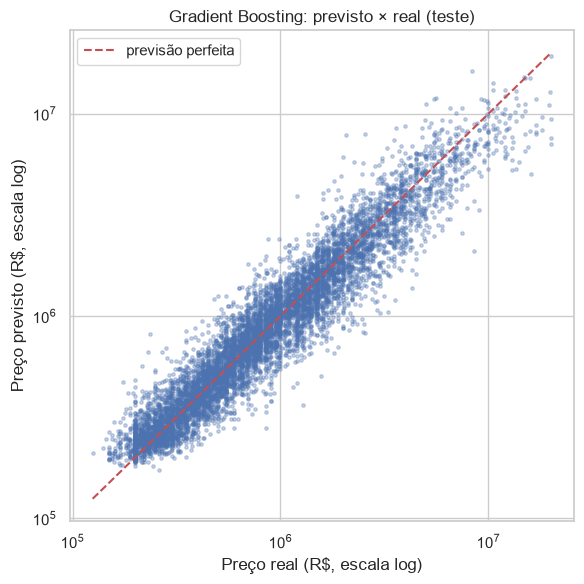

In [24]:
previsto_gb = np.exp(modelo_gb.predict(X_teste))
real = np.exp(y_teste)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real, previsto_gb, s=6, alpha=0.3, color="#4C72B0")
limites = [real.min(), real.max()]
ax.plot(limites, limites, "--", color="#C44E52", label="previsão perfeita")
ax.set(xscale="log", yscale="log", title="Gradient Boosting: previsto × real (teste)",
       xlabel="Preço real (R$, escala log)", ylabel="Preço previsto (R$, escala log)")
ax.legend()
plt.tight_layout()
plt.show()

Os pontos se concentram ao redor da diagonal em toda a faixa de preços, de imóveis de R$ 150 mil a vários milhões, sem um viés sistemático evidente. A dispersão restante vem de fatores que a base não registra: andar, vista, estado de conservação, idade do prédio e a margem de negociação embutida no preço anunciado.

## 8.9 Quais atributos mais importam?

A **importância por permutação** mede quanto o erro do modelo piora quando os valores de um atributo são embaralhados (o que destrói a informação dele). Quanto maior a piora, mais o modelo depende daquele atributo. A medida é calculada no conjunto de teste, sobre as colunas originais (antes do *one-hot*), o que facilita a leitura.

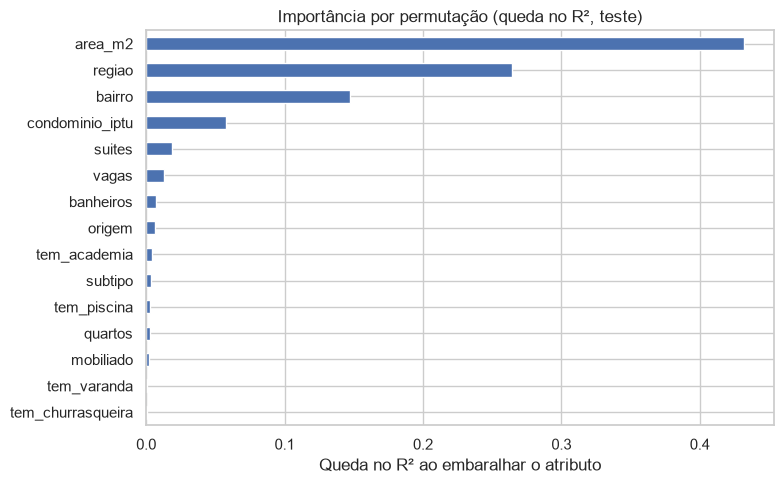

In [25]:
from sklearn.inspection import permutation_importance

importancia = permutation_importance(modelo_gb, X_teste, y_teste, n_repeats=5,
                                     random_state=SEMENTE, scoring="r2")
importancia = pd.Series(importancia.importances_mean, index=X_teste.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importancia.plot.barh(ax=ax, color="#4C72B0")
ax.set(title="Importância por permutação (queda no R², teste)", xlabel="Queda no R² ao embaralhar o atributo")
plt.tight_layout()
plt.show()

Como esperado pela análise exploratória, **área** e **localização** (região e bairro) são os atributos dominantes, seguidos de **condomínio + IPTU** e, em menor grau, suítes e vagas.

O número de quartos e os itens de lazer aparecem com importância baixa, mas isso não quer dizer que não influenciam o preço (a seção 7.4 mostrou que influenciam). Acontece que a informação deles já está quase toda contida em outros atributos: imóveis com mais quartos são maiores, e condomínios com piscina e academia têm condomínio mais caro. Ao embaralhar só os quartos, o modelo continua sabendo a área, e por isso quase não perde desempenho. Isso é coerente com o funcionamento do mercado imobiliário e reforça que o modelo aprendeu relações reais, e não ruído ou vazamento.

# 9. Base final para modelagem

## 9.1 Gravação

A base limpa é gravada em CSV para as próximas etapas do trabalho. Gravamos a versão da seção 6, **antes** do agrupamento de bairros e da imputação. Essas transformações dependem da divisão treino/teste e devem ser refeitas, dentro do *pipeline*, em cada nova modelagem.

Usamos `encoding="utf-8-sig"` para que os acentos apareçam corretamente ao abrir o arquivo no Excel.

In [26]:
ARQUIVO_FINAL = "quintoandar_rio_modelagem_Vinicius_Machado.csv"
df.to_csv(ARQUIVO_FINAL, index=False, encoding="utf-8-sig")

# Conferência: o arquivo relido precisa ser igual à base em memória
relido = pd.read_csv(ARQUIVO_FINAL, encoding="utf-8-sig")
pd.testing.assert_frame_equal(relido, df, check_dtype=False)

print(f"Arquivo gravado: {ARQUIVO_FINAL} ({relido.shape[0]:,} linhas x {relido.shape[1]} colunas)")

Arquivo gravado: quintoandar_rio_modelagem_Vinicius_Machado.csv (41,300 linhas x 16 colunas)


## 9.2 Dicionário da base final

| Coluna | Tipo | Observação |
|---|---|---|
| `preco` | inteiro (R$) | **Alvo**. Modelar em `log` |
| `origem` | categoria | `quintoandar` ou `classificado` |
| `subtipo` | categoria | `apartamento`, `kitnet`, `casa`, `casa_condominio` |
| `bairro` | categoria | Agrupar bairros raros a partir do treino (seção 8.2) |
| `regiao` | categoria | 6 regiões, sem ausentes |
| `area_m2` | inteiro (m²) | Sem ausentes |
| `quartos`, `banheiros`, `vagas` | número | Poucos ausentes, imputar no *pipeline* |
| `suites` | número | Ausente onde havia mais suítes que quartos |
| `condominio_iptu` | número (R$/mês) | Ausente onde o valor era impossível; zero é válido |
| `tem_piscina`, `tem_churrasqueira`, `tem_academia`, `tem_varanda`, `mobiliado` | 0/1 | Sem ausentes |

# 10. Conclusão

## 10.1 Resposta à etapa 1

**Sim, temos um conjunto de dados adequado para prever o preço de imóveis.** A base de anúncios de venda do QuintoAndar no Rio de Janeiro (outubro de 2026) foi escolhida entre quatro fontes porque é a única que reúne, ao mesmo tempo, preço de **venda** como alvo, atributos ricos, o maior volume, dados atuais e acesso reprodutível por URL pública.

Depois da limpeza, que removeu apenas 0,36% dos anúncios (150 de 41.450) e apagou valores impossíveis sem descartar os anúncios, a prova de conceito mostrou que:

- os atributos disponíveis explicam cerca de 91% da variação de `log(preço)`;
- um modelo de Gradient Boosting reduz o erro percentual médio de 33% (referência "m² do bairro × área") para 21%;
- o desempenho é estável na validação cruzada (R² entre 0,909 e 0,916 nas 5 dobras);
- os atributos mais importantes (área e localização) são os que se esperaria do mercado, o que indica que não há vazamento de dados.

## 10.2 Limitações conhecidas

- **Preço anunciado não é preço de venda.** O valor fechado costuma ser menor que o pedido. Para estimar o valor real de transação, seria interessante complementar com dados de transações (por exemplo, pela biblioteca `dadosimob`).
- **Um único dia de coleta.** O modelo descreve o mercado de outubro de 2026 e precisaria ser retreinado periodicamente.
- **Atributos ausentes na fonte.** Andar, idade do imóvel, vista, estado de conservação e coordenadas geográficas ajudariam a reduzir o erro restante.
- **Cobertura geográfica.** A base cobre o município do Rio de Janeiro. Aplicar o modelo a outras cidades exigiria outros dados.

## 10.3 Próximos passos

1. Ajustar os hiperparâmetros do Gradient Boosting e testar outros algoritmos (Random Forest, XGBoost, LightGBM).
2. Criar atributos derivados, como área por quarto ou a mediana do m² do bairro calculada no treino.
3. Analisar os erros por região e faixa de preço para identificar onde o modelo é menos confiável.